In [7]:
# import packages
import os
import pickle
from starmap.config import Config
from starmap.pipeline import Pipeline

# Config Setting
there are two choices for setting up a config
- start from fresh (type in all the params by yourself for your first run)
- initialize with existing saved config from your last run

In [4]:
# choice 1. start from fresh
config = Config(filepath_homedir = "",
                filepath_rawdata = "",
                filepath_codebook = "",
                filepath_dapi = "",
                filepath_nissl = "",
                filepath_dapi_all_z = "",
                round_index = [1, 2, 3], 
                fov_align = 1,
                round_align = 1,
                fov_minmax = [1, 3, 5, 6, 10],
                cellpose_model = 'TN3',
                cellpose_channel = [2, 3],
                SpGene = None, # 'ChAlign', 'RoAlign', 'CbCorrection', 'Normalization', 'bardensrReg', 'GeneCalling', 'Finished'
                SpMask = None, # 'PosReg', 'CellSeg', 'ExpMask', 'Gene2Mask', 'RmvOverlap', 'Finished'
                
                ifov = 1,
                igenes = ["gene1", "gene2", "gene3", "gene4", "nogene1", "nogene2"]
                )

FileNotFoundError: [WinError 3] The system cannot find the path specified: ''

In [6]:
# choice 2. load saved config
filename = 'filepath of config.pickle stored in validation folder'
with open(filename, 'rb') as f:
    config_dict = pickle.load(f)
config = Config(**config_dict)

FileNotFoundError: [Errno 2] No such file or directory: 'filepath of config.pickle stored in validation folder'

In [8]:
# update several setting if needed
config.update_parameters()

NameError: name 'config' is not defined

# Pipline Initialization
here pipeline are auto loaded and prepared for run

In [9]:
pipeline = Pipeline(config)

NameError: name 'config' is not defined

# Run Pipeline
actually run the pipeline through

In [10]:
pipeline.run()
if config.CpMask['RmvOverlap'] and config.remove_overlap:
    if config.grid_stitch:
        os.system('python remove_overlap_mp.py ' + config.filepath_homedir + ' position_reg ' + str(config.dim))
    else:
        os.system('python remove_overlap_mp.py ' + config.filepath_homedir + ' position_corr ' + str(config.dim))

NameError: name 'pipeline' is not defined

In [1]:
import os
import pandas as pd
from datetime import datetime
#from path import path

from starmap.config import Config
from starmap.pipeline import Pipeline

c:\Users\kebsc\Downloads\STARmap_analysis-master\STARmap_analysis-master\analysis_pipeline\starmap\config.py:146: UserWarning: GPU is not detected
  warnings.warn("GPU is not detected")


05/12/2024 13:25:15 restart the pipeline from some point
05/12/2024 13:25:15 ----reload dapi/nissl images
05/12/2024 13:25:15 ----reload dapi/nissl images
05/12/2024 13:25:17 ----reload intermediate data for gene calling
12
2
start loading: \\KebschullLab1\heliamphora\Huihui\Barseq\R1\Pipeline_results\Brain2_gene\\STARmap_output/image_preped.hdf5
8.333333333333334% done loading hdf5 file
16.666666666666668% done loading hdf5 file
25.0% done loading hdf5 file
33.333333333333336% done loading hdf5 file
41.666666666666664% done loading hdf5 file
50.0% done loading hdf5 file
58.333333333333336% done loading hdf5 file
66.66666666666667% done loading hdf5 file
75.0% done loading hdf5 file
83.33333333333333% done loading hdf5 file
91.66666666666667% done loading hdf5 file
100.0% done loading hdf5 file
05/12/2024 13:25:56 ----    finish reloading image spots from: image_preped.hdf5
12
2304
05/12/2024 13:26:01 ----    finish reloading image masks from: image_masks.hdf5
05/12/2024 13:26:01      

KeyboardInterrupt: 

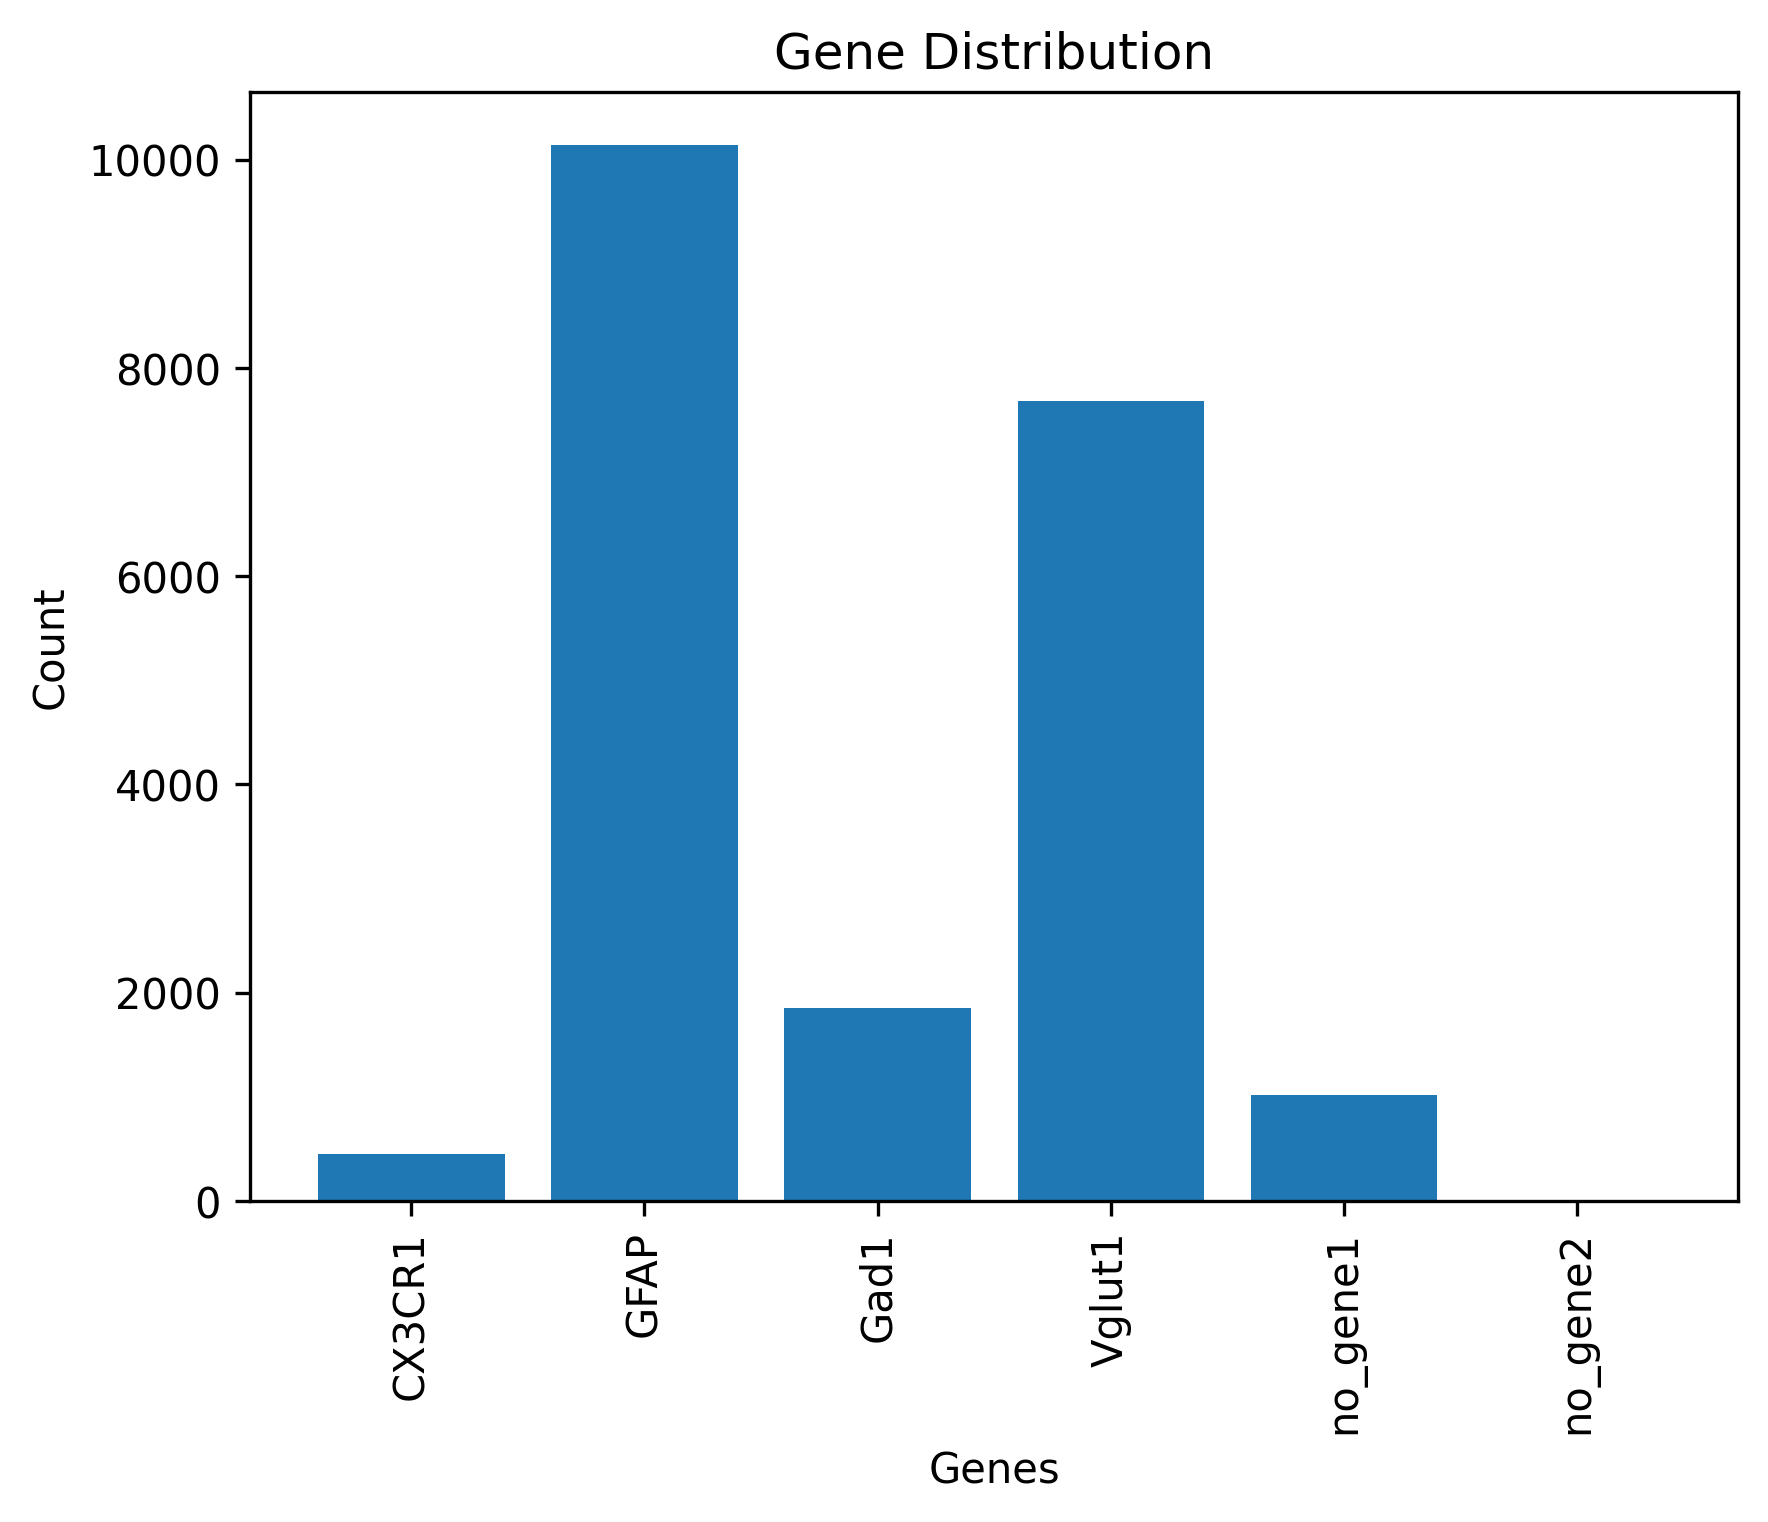

In [13]:
if __name__ == '__main__':
    config = Config(filepath_homedir = r"\\KebschullLab1\heliamphora\Huihui\Barseq\R1\Pipeline_results\Brain2_gene\\",
                    filepath_rawdata = r"\\KebschullLab1\heliamphora\Huihui\Barseq\R1\\",
                    filepath_codebook = r"\\KebschullLab1\heliamphora\Huihui\Barseq\R1\Gene_list.csv",
                    filepath_dapi_all_z = "",
                    filepath_dapi = r"\\KebschullLab1\heliamphora\Huihui\Barseq\R1\round3\all_dapi.nd2",
                    #filepath_nissl = "//KebschullLab2/shareFlash/manjari/MA30/round1_dapi_redo/dapi.nd2",
                    round_index = [1, 2],
                    fov_num = 12, # total number of FOVs
                    fov_align = 7, #field of view to do channel alignment -- has to have a lot of signal 
                    fov_minmax = [5, 6, 2], #representative FOVs to calculate minmax normalization parameters
                    #cellpose_model = 'cyto', #cell segmentation
                    #cellpose_channel = [2, 3], #cell segmentation
                    radius = 50, #radius of the rolling ball background subtraction
                    fdr_thresh = 0.015, # false detection rate
                    expand_pixel = 10, # expand dapi by this much after cell segmentation
                    ifov =0, # not working -- number needs to be smaller than length of FOVs
                    igenes = ["Slc17a6", "Gad1", "Atoh1", "Sox14", "nogene1", "nogene2"], # not_working -- genes in codebook
                    SpGene = 'GeneCalling', # 'ChAlign', 'RoAlign', 'CbCorrection', 'Normalization', 'bardensrReg', 'GeneCalling', 'Finished' # where to begin pipeline for gene calling part
                    #EpGene = "Finished", # where to end pipeline  for gene calling part
                    SpMask = "Finished", # 'PosReg', 'CellSeg', 'ExpMask', 'Gene2Mask', 'RmvOverlap', 'Finished' # where to begin pipeline for cell segmentation part
                    # EpMask = "ExpMask", # where to end pipeline for cell segmentation part
                    grid_stitch = False,
                    bardensr_reg = False,
                    find_param = False,
                    #cellpose_denoise = True, #cell segmentation
                    #remove_overlap = True, #cell segmentation
                    align_method = 'OpenCV',
                    round_num = 2, #number of rounds
                    thresh_refined = 0.8,#; fdrmean: 0.20054059775766364; diff:-0.00054059775766363
                    bardensr_patch_size = (1000, 1000), 
                    bardensr_overlap = (100, 100),
                    bardensr_niter = 10,
                    noisefloor = 0.2
                    )

    pipeline = Pipeline(config)

    pipeline.run()

    if config.CpMask['RmvOverlap'] and config.remove_overlap:
        if config.grid_stitch:
            os.system('python remove_overlap_mp.py ' + config.filepath_homedir + ' position_reg ' + str(config.dim))
        else:
            os.system('python remove_overlap_mp.py ' + config.filepath_homedir + ' position_corr ' + str(config.dim))
        # os.system('python remove_overlap_mp.py %s' % config.filepath_homedir)
    
    pipeline.save()


In [ ]:
gene_called = pd.read_csv(r"\\KebschullLab1\heliamphora\Huihui\Barseq\R1\Pipeline_results\Brain2_gene\STARmap_output\gene_called.csv")

In [ ]:
gene_called

,m0,m1,m2,j,FOV,globX,globY,Names
0,0,39,379,0,0.0,5338.0,379.0,Vglut1
1,0,77,214,0,0.0,5376.0,214.0,Vglut1
2,0,87,70,0,0.0,5386.0,70.0,Vglut1
3,0,135,218,0,0.0,5434.0,218.0,Vglut1
4,0,151,374,0,0.0,5450.0,374.0,Vglut1
...,...,...,...,...,...,...,...,...
23233,0,1564,75,1,11.0,15157.0,33252.0,Gad1
23234,0,1465,90,3,11.0,15058.0,33267.0,Aldh1l1
23235,0,1559,149,3,11.0,15152.0,33326.0,Aldh1l1
23236,0,1465,90,4,11.0,15058.0,33267.0,GFAP


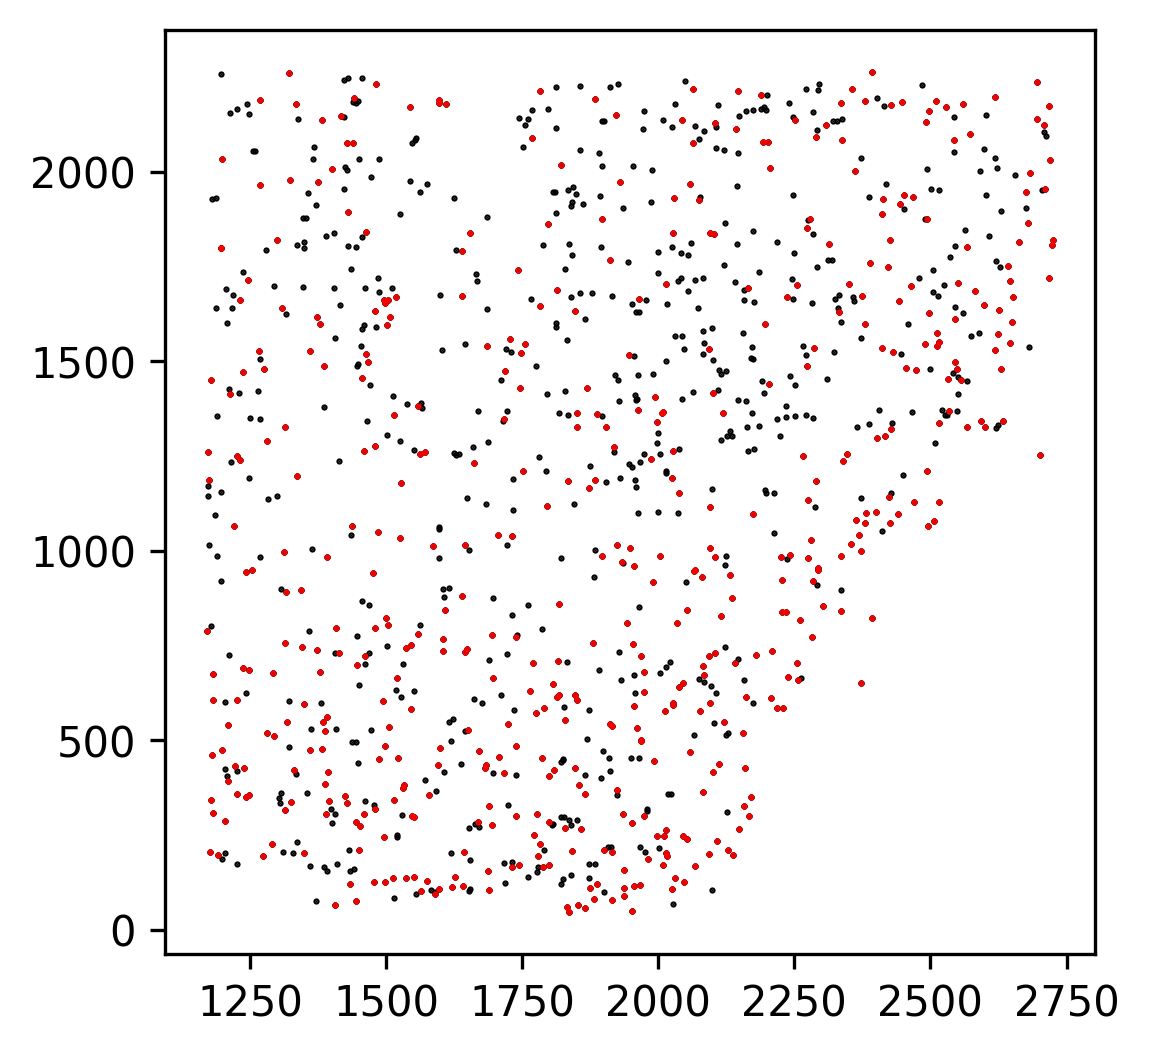

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4,4))
FOV = 1
gene_fov = gene_called[gene_called['FOV']==FOV]
gene_gene = gene_fov[gene_fov['Names'] == 'GFAP']
ax.scatter(gene_fov['globX'], gene_fov['globY'], s= 1, color = 'black', marker = '.')
ax.scatter(gene_gene['globX'], gene_gene['globY'], s= 1, color = 'red', marker = '.')


In [ ]:
pipeline = Pipeline(config)
pipeline

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
def plot_gene_per_cell(config):
    gene_mapped = pd.read_csv(config.filepath_output+'gene_mapped.csv')
    
    gene2cell_fov, unigene2cell_fov = [], []
    for FOV in range(config.fov_num):
        gene_fov = gene_mapped[gene_mapped['FOV']==FOV]
        gene_cell, unigene_cell = [], []
        for CELL in np.unique(gene_fov['cell_number']):
            temp = gene_fov[gene_fov['cell_number']==CELL]
            gene_cell.append(len(temp))
            unigene_cell.append(len(np.unique(temp['Names'])))
        gene2cell_fov.append(np.average(gene_cell))
        unigene2cell_fov.append(np.average(unigene_cell))
    plt.figure()
    if int(config.fov_num*0.2) >5: plt.figure(figsize=(int(config.fov_num*0.2)*2, int(config.fov_num*0.2)))
    bar1 = plt.bar(x=np.arange(config.fov_num), height=gene2cell_fov, width=0.4, label='genes per cell', color='lightblue', tick_label=range(config.fov_num))
    bar2 = plt.bar(x=np.arange(config.fov_num)+0.4, height=unigene2cell_fov, width=0.4, label='unique gene per cell', color='lightcoral')
    # plt.bar_label(bar1)
    # plt.bar_label(bar2)
    plt.title('genes per cell & unique gene per cell')
    plt.xlabel('fov')
    plt.ylabel('num')
    plt.xticks(np.arange(config.fov_num)+0.2, range(config.fov_num))
    plt.legend()

plot_gene_per_cell(config)